# Diffusion denoising of AMD-SD (Hu et al., SPIE 2022)

Runs the published **unsupervised retinal OCT diffusion model** (Hu, Tao & Oguz, *Unsupervised denoising
of retinal OCT with diffusion probabilistic model*, SPIE Medical Imaging 2022; code and checkpoint:
github.com/deweihu/oct_ddpm, MIT licence) on the AMD-SD validation scans, with its **released weights**.

**Two ways of using the same model**

| Mode | What it does | Why |
|---|---|---|
| `onestep` | The noisy scan is treated as the diffusion image at step *t*; the model predicts the noise **once** and it is subtracted. Deterministic. | This is the authors' published inference. |
| `sample` | Full **step-by-step stochastic sampling** from step *t* down to 0, adding fresh random noise at every step (standard DDPM). Different seeds give different outputs. | This is the genuinely **generative** use, where invented or erased structure can appear, and where comparing seeds is a hallucination check. |

**Strength knob:** the step *t* (0-99) plays the role BM3D's sigma played: larger *t* = the model assumes
more noise and removes more. The authors used *t* of about 41-50 for their data.

**Outputs** go to `denoised_cache/<condition>/<scan>.png`, the folder layout `segment_amd_sd.ipynb`
picks up automatically. Finished files are skipped, so the run resumes if interrupted.

**Caveats to report:** the checkpoint was trained on a different OCT system (and on self-fused,
higher-SNR B-scans), so this is a cross-device use of the published model. The authors' self-fusion
pre-processing is not applied (AMD-SD has no neighbouring-slice volumes), matching their own test script.

**Requires:** `torch numpy pillow scipy matplotlib` and `git` (the repo is cloned automatically).

In [1]:
from pathlib import Path
import os, sys, time, subprocess
import numpy as np
from PIL import Image
from scipy import ndimage
import matplotlib.pyplot as plt
import torch

QUICK_TEST = False          # True = 10 scans only, to check everything works

ROOT = Path.cwd().parent if Path.cwd().name == "_analysis" else Path.cwd()
IMG_DIR = ROOT / "images"
DENOISED = Path("denoised_cache")
REPO = Path("oct_ddpm")
W_DEN = 560                 # same width as the BM3D files in denoised_cache

if not REPO.exists():
    subprocess.run(["git", "clone", "https://github.com/deweihu/oct_ddpm.git", str(REPO)], check=True)
sys.path.insert(0, str(REPO / "src"))
from DDPM_Net import Model

DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
if sys.platform == "darwin":
    subprocess.Popen(["caffeinate", "-i", "-w", str(os.getpid())])

model = Model().to(DEVICE)
model.load_state_dict(torch.load(REPO / "ckpts" / "DDPM_oct_dataset2_2021-07-08.pt", map_location=DEVICE))
model.eval()
print("device:", DEVICE, "| parameters:", f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f} M")

Cloning into 'oct_ddpm'...


device: mps | parameters: 2.2 M


## 1. Denoising functions

AMD-SD scans are 380 x 560 px; the network needs 512 x 512. Each scan is padded in depth (mirror) to
512 and processed as two overlapping 512-wide windows, blended smoothly so no seam appears. Intensities
are scaled to [-1, 1] as in the authors' test code and mapped back to the scan's own range afterwards.

In [2]:
import numpy as np, torch
T = 100
BETAS = torch.tensor(np.linspace(1e-4, 0.006, T)).float()     # schedule used with this checkpoint in the authors' DDPM_test.py
ALPHAS = 1 - BETAS
ABAR = torch.cumprod(ALPHAS, 0)

def _windows(W, size=512):
    return [0] if W <= size else [0, W - size]

def _weights(W, starts, size=512):
    """Feathered blending weights so overlapping windows leave no seam."""
    w = np.zeros((len(starts), W))
    for k, s in enumerate(starts):
        ramp = np.ones(size)
        if len(starts) == 2:
            ov = starts[0] + size - starts[1]          # overlap width
            if k == 0:
                ramp[size - ov:] = np.linspace(1, 0, ov)
            else:
                ramp[:ov] = np.linspace(0, 1, ov)
        w[k, s:s + size] = ramp
    return w / w.sum(0, keepdims=True)

def _to_windows(img, starts, size=512):
    H = img.shape[0]
    out = []
    for s in starts:
        win = np.empty((size, size), np.float32)
        win[:H] = img[:, s:s + size]
        win[H:] = np.flipud(img[2 * H - size:H, s:s + size])  # reflect-pad depth to 512
        out.append(win)
    return np.stack(out)[:, None]

@torch.no_grad()
def denoise(model, img_u8, t, mode="onestep", seed=0, device="cpu"):
    """img_u8: (H, W) uint8 scan, H <= 512. Returns uint8 of the same size and intensity scale."""
    x = img_u8.astype(np.float32); lo, hi = float(x.min()), float(x.max())
    x = 2 * (x - lo) / max(hi - lo, 1e-6) - 1                     # [-1, 1], as in the authors' test loader
    H, W = x.shape
    starts = _windows(W); wts = _weights(W, starts)
    xt = torch.from_numpy(_to_windows(x, starts)).to(device)
    ab = ABAR.to(device); be = BETAS.to(device); al = ALPHAS.to(device)
    if mode == "onestep":                                          # the published method
        eps = model(xt, torch.full((len(starts),), t, device=device))
        x0 = (xt - torch.sqrt(1 - ab[t]) * eps) / torch.sqrt(ab[t])
    elif mode == "sample":                                         # stochastic ancestral DDPM sampling t -> 0
        g = torch.Generator(device="cpu").manual_seed(seed)
        for s in range(t, -1, -1):
            eps = model(xt, torch.full((len(starts),), s, device=device))
            x0 = ((xt - torch.sqrt(1 - ab[s]) * eps) / torch.sqrt(ab[s])).clamp(-1.5, 1.5)
            if s == 0:
                break
            c1 = torch.sqrt(ab[s - 1]) * be[s] / (1 - ab[s])
            c2 = torch.sqrt(al[s]) * (1 - ab[s - 1]) / (1 - ab[s])
            var = be[s] * (1 - ab[s - 1]) / (1 - ab[s])
            z = torch.randn(xt.shape, generator=g).to(device)
            xt = c1 * x0 + c2 * xt + torch.sqrt(var) * z
    else:
        raise ValueError(mode)
    x0 = x0[:, 0, :H].cpu().numpy()
    out = np.zeros((H, W))
    for k, s in enumerate(starts):
        out[:, s:s + 512] += x0[k] * wts[k, s:s + 512]
    out = (out + 1) / 2 * (hi - lo) + lo                           # back to the scan's own intensity scale
    return np.clip(out, 0, 255).astype(np.uint8)

In [3]:
def load_scan(name):
    eye = name.split("_")[0]
    a = np.asarray(Image.open(IMG_DIR / eye / name).convert("RGB"))[:, :W_DEN]
    return a.mean(-1).astype(np.uint8)

val_names = [Path(l.strip()).name for l in open(ROOT / "validation.txt") if l.strip()]
eval_names = [n for n in val_names if (DENOISED / f"{Path(n).stem}_s0.2.png").exists()]   # same 626 scans as before
if QUICK_TEST:
    eval_names = eval_names[:10]
print(f"{len(eval_names)} validation scans (the ones evaluated in the segmentation notebook)")

# speed check
probe = load_scan(eval_names[0])
t0 = time.time(); denoise(model, probe, 48, "onestep", device=DEVICE); t_one = time.time() - t0
t0 = time.time(); denoise(model, probe, 5, "sample", device=DEVICE); t_step = (time.time() - t0) / 6
print(f"one-step: {t_one:.2f} s/scan | sampling: about {t_step:.2f} s per step per scan")

626 validation scans (the ones evaluated in the segmentation notebook)
one-step: 0.97 s/scan | sampling: about 0.23 s per step per scan


## 2. Calibration: what do the strengths look like, and how do they compare with BM3D?

Top: the scan, BM3D at the noise level (0.037) and strong (0.2), then one-step diffusion at several *t*.
Bottom: two stochastic samples at the same *t* with different seeds, and their difference (bright =
places where the two samples disagree, i.e. where the model is generating rather than recovering).

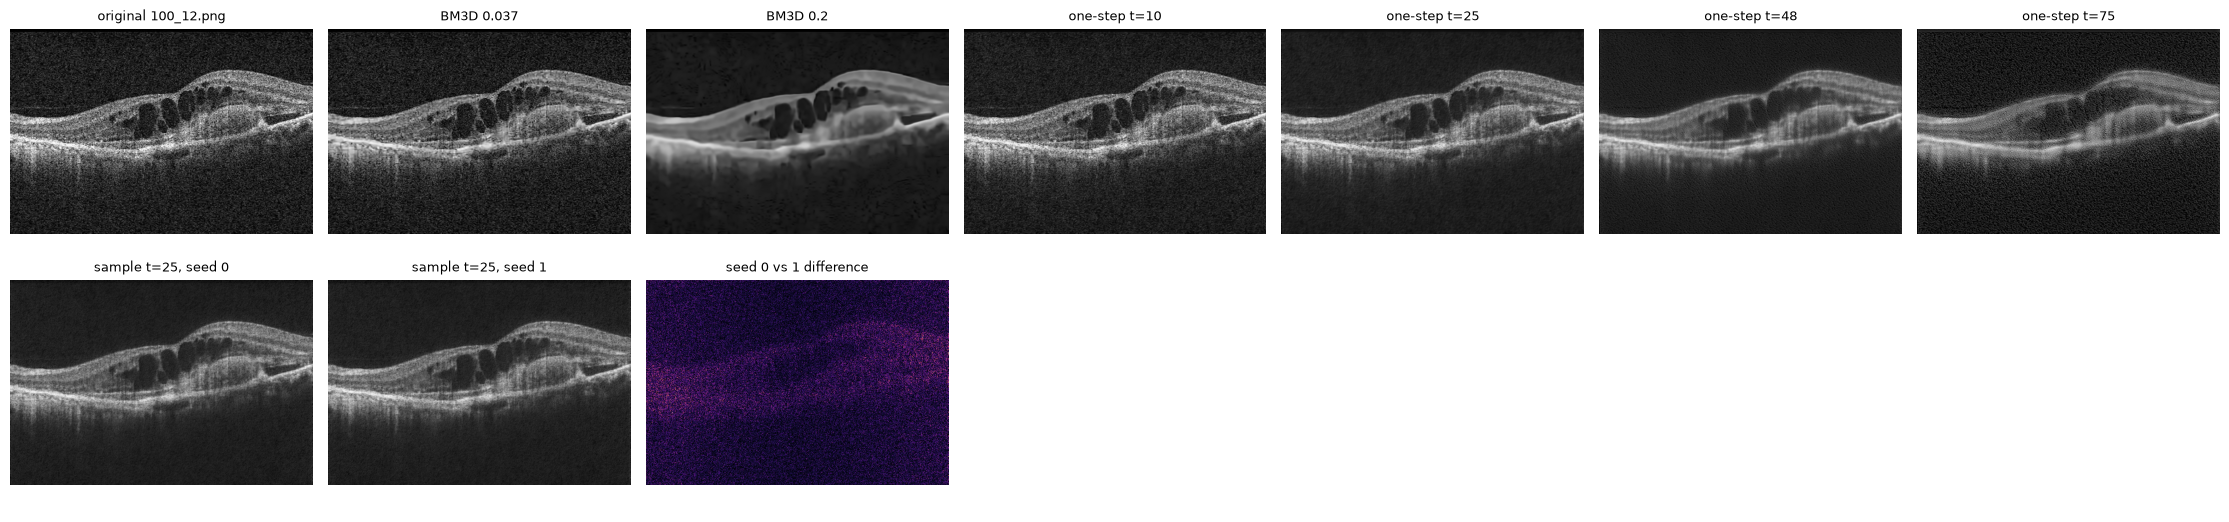

In [4]:
CAL_TS = [10, 25, 48, 75]
SAMPLE_T_CAL = 25
name = eval_names[min(3, len(eval_names) - 1)]
img = load_scan(name)
bm = {s: np.asarray(Image.open(DENOISED / f"{Path(name).stem}_s{s}.png")) for s in ["0.037", "0.2"]}
one = {t: denoise(model, img, t, "onestep", device=DEVICE) for t in CAL_TS}
s0 = denoise(model, img, SAMPLE_T_CAL, "sample", seed=0, device=DEVICE)
s1 = denoise(model, img, SAMPLE_T_CAL, "sample", seed=1, device=DEVICE)

top = [(img, f"original {name}"), (bm["0.037"], "BM3D 0.037"), (bm["0.2"], "BM3D 0.2")] + \
      [(one[t], f"one-step t={t}") for t in CAL_TS]
bottom = [(s0, f"sample t={SAMPLE_T_CAL}, seed 0"), (s1, f"sample t={SAMPLE_T_CAL}, seed 1"),
          (np.abs(s0.astype(int) - s1.astype(int)), "seed 0 vs 1 difference")]
fig, axes = plt.subplots(2, len(top), figsize=(3.2 * len(top), 5.4))
for ax, (im, title) in zip(axes[0], top):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255); ax.set_title(title, fontsize=9); ax.axis("off")
for ax, (im, title) in zip(axes[1], bottom):
    ax.imshow(im, cmap="gray" if "difference" not in title else "magma"); ax.set_title(title, fontsize=9); ax.axis("off")
for ax in axes[1][len(bottom):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

In [5]:
# Remaining noise after each method, on the same log scale used for BM3D (Immerkaer estimator).
# This places each diffusion strength next to the BM3D settings: similar numbers = similar smoothing.
def log01(u8):
    return np.log1p(u8.astype(np.float64)) / np.log(256.0)

def noise_est(img):
    k = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], float)
    h, w = img.shape
    return np.sqrt(np.pi / 2) * np.abs(ndimage.convolve(img, k))[1:-1, 1:-1].sum() / (6 * (w - 2) * (h - 2))

sample_names = eval_names[:: max(1, len(eval_names) // 15)][:15]
rows = {"original": [], "BM3D 0.037": [], "BM3D 0.05": [], "BM3D 0.1": [], "BM3D 0.2": []} | {f"one-step t={t}": [] for t in CAL_TS}
for n in sample_names:
    im = load_scan(n)
    rows["original"].append(noise_est(log01(im)))
    for s in ["0.037", "0.05", "0.1", "0.2"]:
        rows[f"BM3D {s}"].append(noise_est(log01(np.asarray(Image.open(DENOISED / f"{Path(n).stem}_s{s}.png")))))
    for t in CAL_TS:
        rows[f"one-step t={t}"].append(noise_est(log01(denoise(model, im, t, "onestep", device=DEVICE))))
print(f"Remaining noise (log scale), median over {len(sample_names)} scans; lower = smoother")
for k, v in rows.items():
    print(f"  {k:16s} {np.median(v):.4f}")

Remaining noise (log scale), median over 15 scans; lower = smoother
  original         0.0371
  BM3D 0.037       0.0240
  BM3D 0.05        0.0168
  BM3D 0.1         0.0036
  BM3D 0.2         0.0012
  one-step t=10    0.0172
  one-step t=25    0.0063
  one-step t=48    0.0293
  one-step t=75    0.0974


## 3. Denoise all evaluated validation scans

Conditions (each becomes a folder in `denoised_cache/` and a row in the segmentation results):
- `ddpm1_t<t>`: one-step, for each *t* in `ONESTEP_TS`
- `ddpmS_t<t>_seed<k>`: stochastic sampling at `SAMPLE_T`, one folder per seed

Sampling costs one network pass per step, so it is much slower than one-step: the cell prints the time
left. Start with the defaults; add seeds later if the seed comparison looks interesting.

In [ ]:
ONESTEP_TS = [10, 25, 48, 75]
SAMPLE_T = 25
SEEDS = [0, 1]

jobs = [(f"ddpm1_t{t}", t, "onestep", 0) for t in ONESTEP_TS] + \
       [(f"ddpmS_t{SAMPLE_T}_seed{k}", SAMPLE_T, "sample", k) for k in SEEDS]
for cond, t, mode, seed in jobs:
    out_dir = DENOISED / cond; out_dir.mkdir(parents=True, exist_ok=True)
    todo = [n for n in eval_names if not (out_dir / f"{Path(n).stem}.png").exists()]
    print(f"{cond}: {len(eval_names) - len(todo)} done, {len(todo)} to go")
    t0 = time.time()
    for i, n in enumerate(todo):
        Image.fromarray(denoise(model, load_scan(n), t, mode, seed=seed, device=DEVICE)).save(out_dir / f"{Path(n).stem}.png")
        if (i + 1) % 50 == 0 or i + 1 == len(todo):
            rate = (time.time() - t0) / (i + 1)
            print(f"  {i + 1}/{len(todo)}  {rate:.1f}s/scan  about {rate * (len(todo) - i - 1) / 60:.0f} min left")
print("all conditions done")

ddpm1_t10: 0 done, 626 to go
  50/626  0.2s/scan  about 2 min left
  100/626  0.2s/scan  about 2 min left
  150/626  0.2s/scan  about 2 min left
  200/626  0.2s/scan  about 2 min left
  250/626  0.2s/scan  about 2 min left
  300/626  0.2s/scan  about 1 min left
  350/626  0.2s/scan  about 1 min left
  400/626  0.2s/scan  about 1 min left
  450/626  0.2s/scan  about 1 min left
  500/626  0.2s/scan  about 1 min left
  550/626  0.2s/scan  about 0 min left
  600/626  0.2s/scan  about 0 min left
  626/626  0.2s/scan  about 0 min left
ddpm1_t25: 0 done, 626 to go
  50/626  0.2s/scan  about 2 min left
  100/626  0.2s/scan  about 2 min left
  150/626  0.2s/scan  about 2 min left
  200/626  0.2s/scan  about 2 min left
  250/626  0.2s/scan  about 2 min left
  300/626  0.2s/scan  about 1 min left
  350/626  0.2s/scan  about 1 min left
  400/626  0.2s/scan  about 1 min left
  450/626  0.2s/scan  about 1 min left
  500/626  0.2s/scan  about 1 min left
  550/626  0.2s/scan  about 0 min left
  600/62

## 4. How much do two stochastic samples disagree?

Same scan, same strength, different random seed. Where the two outputs differ, the model is
**generating** detail rather than recovering it from the scan. This is a first, ground-truth-free look
at hallucination; the segmentation notebook will then count which **lesions** change between seeds.

In [ ]:
if len(SEEDS) >= 2:
    da, db = DENOISED / f"ddpmS_t{SAMPLE_T}_seed{SEEDS[0]}", DENOISED / f"ddpmS_t{SAMPLE_T}_seed{SEEDS[1]}"
    diffs = []
    for n in eval_names:
        a = np.asarray(Image.open(da / f"{Path(n).stem}.png")).astype(int)
        b = np.asarray(Image.open(db / f"{Path(n).stem}.png")).astype(int)
        diffs.append(np.abs(a - b).mean())
    diffs = np.array(diffs)
    print(f"mean absolute difference between seeds (0-255 scale): median {np.median(diffs):.2f}, "
          f"95th percentile {np.percentile(diffs, 95):.2f}")
    worst = [eval_names[i] for i in np.argsort(-diffs)[:3]]
    fig, axes = plt.subplots(len(worst), 4, figsize=(16, 3 * len(worst)), squeeze=False)
    for r, n in enumerate(worst):
        a = np.asarray(Image.open(da / f"{Path(n).stem}.png")); b = np.asarray(Image.open(db / f"{Path(n).stem}.png"))
        for c, (im, tt) in enumerate([(load_scan(n), f"{n} original"), (a, "seed 0"), (b, "seed 1"),
                                      (np.abs(a.astype(int) - b.astype(int)), "difference")]):
            axes[r, c].imshow(im, cmap="magma" if tt == "difference" else "gray"); axes[r, c].set_title(tt, fontsize=9)
            axes[r, c].axis("off")
    plt.tight_layout(); plt.show()

## Next

1. Open `segment_amd_sd.ipynb`, **File > Reload Notebook from Disk**, and **Run All**. Training is
   skipped (checkpoint exists); section 4 finds the new `ddpm...` folders and evaluates them next to
   BM3D. Let every condition here finish first: the segmentation notebook only uses scans available in
   **all** conditions.
2. Compare the `ddpm1_t*` rows with the BM3D rows at similar remaining noise (section 2 table).
3. The seed folders give the first **lesion-level** hallucination check: lesions found with one seed
   but not the other.
4. For the Experiment B logic (training on diffusion-denoised scans), the training scans would also
   need denoising; that is a later, longer run.